In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import sys
import subprocess
import joblib
from collections import Counter

try:
    import methcomp
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "methcomp"])
    import methcomp

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
    import xgboost as xgb

from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

         R       S       T      U      V      W  Glucose
0   165.79  169.34   86.86  43.53  21.73  12.95    115.0
10  235.22  222.92  108.29  54.41  27.66  15.31    124.0
20  198.38  197.20   95.88  47.48  23.71  14.13    129.0
30  165.79  169.34   83.48  41.55  20.74  11.77    106.2
40  181.38  218.64  102.65  50.45  24.70  14.13    115.3
50  174.29  212.21   98.14  48.47  23.71  12.95    117.1


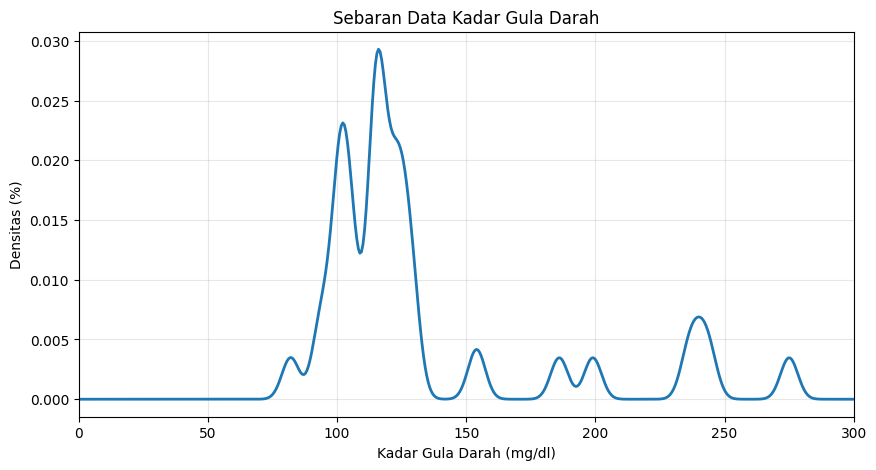

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/glucoband/nir_glucose.csv")
print(df.iloc[[0, 10, 20, 30, 40, 50]])



from scipy.stats import gaussian_kde

glucose = df['Glucose'].dropna()

kde = gaussian_kde(glucose, bw_method=0.07)

x = np.linspace(0, 300, 500)
y = kde(x)

plt.figure(figsize=(10, 5))
plt.plot(x, y, linestyle='-', linewidth=2)

plt.xlabel('Kadar Gula Darah (mg/dl)')
plt.ylabel('Densitas (%)')
plt.title('Sebaran Data Kadar Gula Darah')
plt.xlim(0, 300)
plt.grid(True, alpha=0.3)

plt.show()


features = ['R', 'S', 'T', 'U', 'V', 'W']
X = df[features]
y = df['Glucose']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

def evaluate_model(model, X_train, y_train, X_test, y_test, name):

    y_pred_train = model.predict(X_train)
    if name == "PLS": y_pred_train = y_pred_train.ravel()

    y_pred_test = model.predict(X_test)
    if name == "PLS": y_pred_test = y_pred_test.ravel()

    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    r2_train = r2_score(y_train, y_pred_train)

    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    r2_test = r2_score(y_test, y_pred_test)
    mae_test = mean_absolute_error(y_test, y_pred_test)

    print(f"--- {name} ---")
    print(f"Train -> RMSE: {rmse_train:.2f}, R2: {r2_train:.2f}")
    print(f"Test  -> RMSE: {rmse_test:.2f},  R2: {r2_test:.2f}")
    print(f"Gap R2: {r2_train - r2_test:.2f}")
    print("")

    return {
        "pred": y_pred_test,
        "rmse": rmse_test,
        "r2": r2_test,
        "mae": mae_test
    }

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# A. PLS REGRESSION
best_pls_rmse = np.inf
best_pls = None
best_n = 0
for n in range(1, len(features) + 1):
    pls = PLSRegression(n_components=n)
    y_cv = cross_val_predict(pls, scaler.fit_transform(X), y, cv=kf)
    rmse = np.sqrt(mean_squared_error(y, y_cv))
    if rmse < best_pls_rmse:
        best_pls_rmse = rmse
        best_pls = pls
        best_n = n

best_pls.fit(X_train_s, y_train)
results[f"PLS (n={best_n})"] = evaluate_model(best_pls, X_train_s, y_train, X_test_s, y_test, "PLS")

# B. RANDOM FOREST
rf = RandomForestRegressor(n_estimators=300, max_depth=None, random_state=42)
rf.fit(X_train_s, y_train)
results["Random Forest"] = evaluate_model(rf, X_train_s, y_train, X_test_s, y_test, "Random Forest")


# C. XGBOOST
xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)
xgb_model.fit(X_train_s, y_train)
results["XGBoost"] = evaluate_model(xgb_model, X_train_s, y_train, X_test_s, y_test, "XGBoost")
joblib.dump(xgb_model, "xgboost_model.joblib")
xgb_model.save_model("xgboost_model.json")


--- PLS ---
Train -> RMSE: 39.28, R2: 0.32
Test  -> RMSE: 50.83,  R2: -0.12
Gap R2: 0.44

--- Random Forest ---
Train -> RMSE: 5.47, R2: 0.99
Test  -> RMSE: 10.12,  R2: 0.96
Gap R2: 0.03

--- XGBoost ---
Train -> RMSE: 1.23, R2: 1.00
Test  -> RMSE: 21.19,  R2: 0.81
Gap R2: 0.19



In [ ]:
import numpy as np
import pandas as pd

# nilai aktual
y_true = y_test.values
m = len(y_true)

# prediksi model
y_pred_pls = best_pls.predict(X_test_s).ravel()
y_pred_rf = rf.predict(X_test_s)
y_pred_xgb = xgb_model.predict(X_test_s)
def manual_table(y_true, y_pred, n_sample=None):
    if n_sample is None:
        n_sample = len(y_true)

    rows = []

    for i in range(n_sample):
        yi = y_true[i]
        xi = y_pred[i]

        error = xi - yi
        abs_error = abs(error)
        sq_error = error**2

        rows.append({
            "No": i+1,
            "Yi (Aktual)": yi,
            "Xi (Prediksi)": xi,
            "Xi-Yi": error,
            "|Xi-Yi|": abs_error,
            "(Xi-Yi)^2": sq_error
        })

    df = pd.DataFrame(rows)
    return df.round(3)
def manual_metrics(y_true, y_pred):

    m = len(y_true)

    # MAE
    mae = np.sum(np.abs(y_pred - y_true)) / m

    # RMSE
    rmse = np.sqrt(np.sum((y_pred - y_true)**2) / m)

    # R2
    y_mean = np.mean(y_true)

    rss = np.sum((y_pred - y_true)**2)
    tss = np.sum((y_true - y_mean)**2)

    r2 = 1 - (rss/tss)

    return mae, rmse, r2, rss, tss, y_mean
pls_table = manual_table(y_true, y_pred_pls, n_sample=m)
rf_table = manual_table(y_true, y_pred_rf, n_sample=m)
xgb_table = manual_table(y_true, y_pred_xgb, n_sample=m)

print("PLS Example Calculation")
print(pls_table)

print("\nRandom Forest Example Calculation")
print(rf_table)

print("\nXGBoost Example Calculation")
print(xgb_table)

pls_mae, pls_rmse, pls_r2, pls_rss, pls_tss, pls_mean = manual_metrics(y_true, y_pred_pls)
rf_mae, rf_rmse, rf_r2, rf_rss, rf_tss, rf_mean = manual_metrics(y_true, y_pred_rf)
xgb_mae, xgb_rmse, xgb_r2, xgb_rss, xgb_tss, xgb_mean = manual_metrics(y_true, y_pred_xgb)

print("\n=== Manual Evaluation Results ===")

print("\nPLS Regression")
print("MAE:", pls_mae)
print("RMSE:", pls_rmse)
print("R2:", pls_r2)

print("\nRandom Forest")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2:", rf_r2)

print("\nXGBoost")
print("MAE:", xgb_mae)
print("RMSE:", xgb_rmse)
print("R2:", xgb_r2)

print("\n=== Components of R2 Calculation ===")

print("\nPLS")
print("Mean Y:", pls_mean)
print("RSS:", pls_rss)
print("TSS:", pls_tss)

print("\nRandom Forest")
print("Mean Y:", rf_mean)
print("RSS:", rf_rss)
print("TSS:", rf_tss)

print("\nXGBoost")
print("Mean Y:", xgb_mean)
print("RSS:", xgb_rss)
print("TSS:", xgb_tss)

pls_table.to_csv("pls_manual_calculation.csv", index=False)
rf_table.to_csv("rf_manual_calculation.csv", index=False)
xgb_table.to_csv("xgb_manual_calculation.csv", index=False)

IndexError: index 18 is out of bounds for axis 0 with size 18

In [ ]:
sorted_models = sorted(results.items(), key=lambda x: x[1]['rmse'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, res) in zip(axes, sorted_models):
    ax.scatter(y_test, res["pred"], edgecolors="k", alpha=0.7)
    min_v = min(y_test.min(), res["pred"].min())
    max_v = max(y_test.max(), res["pred"].max())
    ax.plot([min_v, max_v], [min_v, max_v], "r--")
    ax.set_title(f"{name}\nRMSE={res['rmse']:.2f}, R²={res['r2']:.2f}, MAE={res['mae']:2f}")
    ax.set_xlabel("Reference (mg/dL)")
    ax.set_ylabel("Predicted (mg/dL)")
    ax.grid(alpha=0.3)
    print(f"{name}: RMSE={res['rmse']:.2f}, R²={res['r2']:.2f}, MAE={res['mae']:2f}")

plt.tight_layout()
plt.show()


for name, res in sorted_models:
    mean = (y_test + res["pred"]) / 2
    diff = res["pred"] - y_test

    md = np.mean(diff)
    sd = np.std(diff)
    upper = md + 1.96 * sd
    lower = md - 1.96 * sd

    plt.figure(figsize=(7, 5))
    plt.scatter(mean, diff, alpha=0.7)

    plt.axhline(md, color='r', linestyle='--', label='Mean Bias')
    plt.axhline(upper, color='gray', linestyle='--', label='Upper LOA')
    plt.axhline(lower, color='gray', linestyle='--', label='Lower LOA')


    x_pos = mean.max()

    plt.text(x_pos, md, f"Mean Bias = {md:.2f}",
             va='bottom', ha='right', color='r')

    plt.text(x_pos, upper, f"+1.96 SD = {upper:.2f}",
             va='bottom', ha='right', color='gray')

    plt.text(x_pos, lower, f"-1.96 SD = {lower:.2f}",
             va='top', ha='right', color='gray')

    plt.xlabel("Mean of Reference & Prediction (mg/dL)")
    plt.ylabel("Difference (Pred - Ref)")
    plt.title(f"Bland–Altman Plot\n{name}")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()


def clarke_zone(ref, pred):
    if ref < 70:
        if pred < 70:
            return "A"
        elif pred <= 180:
            return "B"
        else:
            return "E"

    elif 70 <= ref <= 180:
        if abs(pred - ref) <= 0.2 * ref:
            return "A"
        elif pred < 70 or pred > 180:
            return "E"
        else:
            return "B"

    else:
        if pred > 180 and abs(pred - ref) <= 0.2 * ref:
            return "A"
        elif pred >= 70:
            return "B"
        else:
            return "E"


for name, res in sorted_models:
    print(f"\nPlotting for {name}...")

    ref_values = np.array(y_test)
    pred_values = np.array(res["pred"])

    plt.figure(figsize=(6, 6))
    methcomp.clarke(ref_values, pred_values, units="mg/dl")
    plt.title(f"Clarke Error Grid - {name}")
    plt.tight_layout()
    plt.show()

    zones = [clarke_zone(r, p) for r, p in zip(ref_values, pred_values)]
    zone_counts = Counter(zones)

    total = len(ref_values)

    print("Zone counts:")
    for zone in ["A", "B", "C", "D", "E"]:
        count = zone_counts.get(zone, 0)
        percent = (count / total) * 100
        print(f"  Zone {zone}: {count} ({percent:.2f}%)")
